# Data manipulation

In [114]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import torch
import torch.nn as nn
import torch.optim as optim


In [22]:
df = pd.read_csv('data/student_performance.csv')

print("Początek zbioru danych:")
print(df.head(10))

print("Dataset loaded successfully")

Początek zbioru danych:
   Hours Studied  Previous Scores  Extracurricular Activities  Sleep Hours  \
0              7               99                           1            9   
1              4               82                           0            4   
2              8               51                           1            7   
3              5               52                           1            5   
4              7               75                           0            8   
5              3               78                           0            9   
6              7               73                           1            5   
7              8               45                           1            4   
8              5               77                           0            8   
9              4               89                           0            4   

   Sample Question Papers Practiced  Scores  
0                                 1      91  
1                        

In [34]:
# Rozdzielenie na cechy (X) oraz etykiety (y)
X = df[['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced' ]].values.astype(np.float32)
y = df['Scores'].values.astype(np.float32).reshape(-1, 1)

# Podział na zbiór treningowy, testowy i walidacyjny
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)  # 70% dane treningowe
X_test, X_valid, y_test, y_valid = train_test_split(X_test, y_test, test_size=0.50, random_state=42)   # 15% i 15% - dane testowe i walidacyjne


In [35]:
print(f"Cechy: {X}")
print(f"Etykiety: {y}")

Cechy: [[ 7. 99.  1.  9.  1.]
 [ 4. 82.  0.  4.  2.]
 [ 8. 51.  1.  7.  2.]
 ...
 [ 6. 83.  1.  8.  5.]
 [ 9. 97.  1.  7.  0.]
 [ 7. 74.  0.  8.  1.]]
Etykiety: [[91.]
 [65.]
 [45.]
 ...
 [74.]
 [95.]
 [64.]]


In [43]:
# Tensor PyTorch converting 

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)
X_valid_t = torch.tensor(X_valid, dtype=torch.float32)
y_valid_t = torch.tensor(y_valid, dtype=torch.float32)


In [46]:
print(f"""Dane treningowe przekonwertowane na Tensor PyTorch: 
{X_train_t}""")

Dane treningowe przekonwertowane na Tensor PyTorch: 
tensor([[ 4., 99.,  1.,  6.,  1.],
        [ 6., 90.,  1.,  9.,  3.],
        [ 8., 57.,  0.,  6.,  1.],
        ...,
        [ 9., 48.,  0.,  7.,  6.],
        [ 1., 47.,  0.,  9.,  0.],
        [ 2., 46.,  0.,  6.,  6.]])


# Podstawowa sieć

In [87]:
df.head(12000)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Scores
0,7,99,1,9,1,91
1,4,82,0,4,2,65
2,8,51,1,7,2,45
3,5,52,1,5,2,36
4,7,75,0,8,5,66
...,...,...,...,...,...,...
9995,1,49,1,4,2,23
9996,7,64,1,8,5,58
9997,6,83,1,8,5,74
9998,9,97,1,7,0,95


### Kontener reprezentujący sieć: nn.Sequential


In [102]:
model = nn.Sequential(
  # 1 warstwa
  nn.Linear(5, 32), 
  nn.ReLU(), 

  # 2 warstwa
  nn.Linear(32, 16), 
  nn.ReLU(), 

  # 3 warstwa
  nn.Linear(16, 1),

)

print(f"""Model: 
{model}""")
    


Model: 
Sequential(
  (0): Linear(in_features=5, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)


In [103]:
# Optymalizator ADAM
optimizer = optim.Adam(model.parameters(), lr=0.005)

# Funkcja straty
loss_function = nn.MSELoss() 

In [117]:
epochs = 750
train_loss_history = []
accuracy_history = []
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

    train_loss_history.append(loss.item())

train_loss_history

[4.191983222961426,
 4.191986560821533,
 4.191993236541748,
 4.1920013427734375,
 4.192013263702393,
 4.1920270919799805,
 4.192047119140625,
 4.192070484161377,
 4.192101955413818,
 4.192141056060791,
 4.192199230194092,
 4.192271709442139,
 4.192375659942627,
 4.192508697509766,
 4.192691326141357,
 4.192927360534668,
 4.193245887756348,
 4.193661212921143,
 4.194223403930664,
 4.194962978363037,
 4.195954322814941,
 4.1972761154174805,
 4.199034690856934,
 4.201352596282959,
 4.2043561935424805,
 4.20819091796875,
 4.212860584259033,
 4.21829080581665,
 4.22398567199707,
 4.229188442230225,
 4.232568740844727,
 4.232828140258789,
 4.228935718536377,
 4.221137523651123,
 4.2110185623168945,
 4.201303005218506,
 4.194512844085693,
 4.191961288452148,
 4.193338394165039,
 4.197096347808838,
 4.2011942863464355,
 4.203856468200684,
 4.204107284545898,
 4.202024936676025,
 4.198566913604736,
 4.195072650909424,
 4.192682266235352,
 4.191929817199707,
 4.192629814147949,
 4.19412899017334

## Test modelu 

In [126]:
model.eval()

with torch.no_grad():
  val_preds = model(X_valid_t)
  val_loss = criterion(val_preds, y_valid_t)

  test_preds = model(X_test_t)
  test_loss = criterion(test_preds, y_test_t)

### tensor.numpy()

def calculate_mae(y_true, y_pred): 
    return float(np.mean(np.abs(y_true - y_pred)))



    
print("Validation loss: " + str(val_loss.item()))
print("Test loss: " + str(test_loss.item()))

NameError: name 'tensor' is not defined

# WIZUALIZACJA DANYCH

RuntimeError: addmm: mat1 and mat2 shapes cannot be multiplied (22500x2 and 5x32)

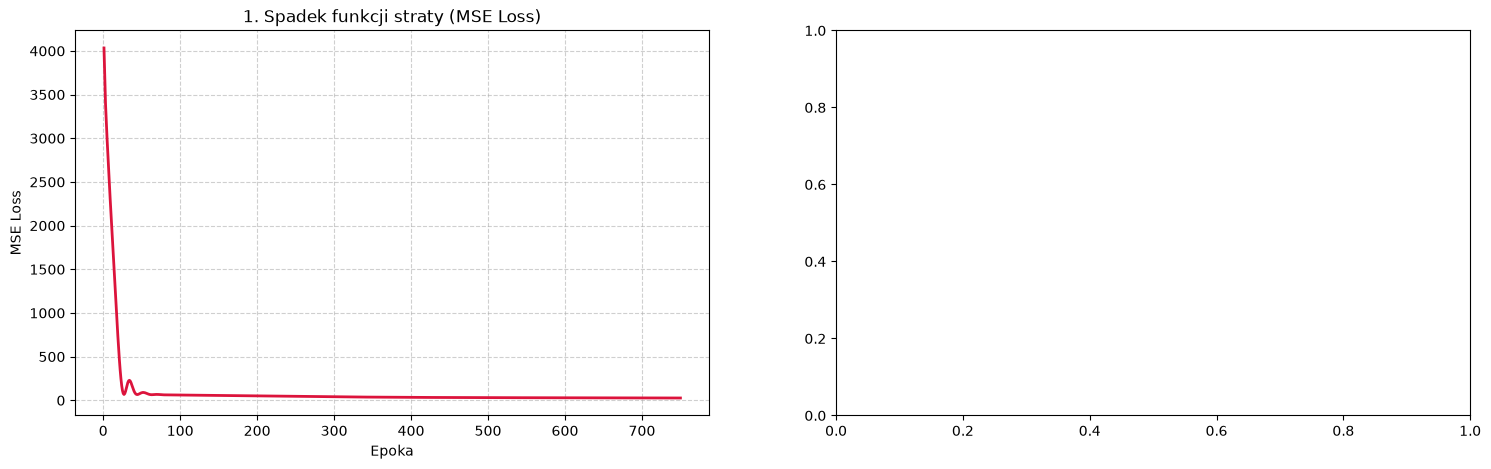

In [125]:

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

axes[0].plot(range(1, epochs + 1), loss_history, color='crimson', linewidth=2)
axes[0].set_title("1. Spadek funkcji straty (MSE Loss)")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("MSE Loss")
axes[0].grid(True, linestyle='--', alpha=0.6)

model.eval()
x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150),
                     np.linspace(y_min, y_max, 150))
grid_tensor = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

with torch.no_grad():
    Z = model(grid_tensor).numpy().reshape(xx.shape)

contour = axes[1].contourf(xx, yy, Z, levels=20, cmap='RdYlBu', alpha=0.6)
axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='bwr_r', edgecolor='k', s=50)
axes[1].set_title("2. Ostateczna granica decyzyjna")
axes[1].set_xlabel("....")
axes[1].set_ylabel(".....")
fig.colorbar(contour, ax=axes[1], label="Przewidywana szansa")

plt.tight_layout()
plt.show()